In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler



In [16]:
# Importing the cleaned data
Sleep_clean = pd.read_csv('../01_Kaggle_Cleaning_EDA/sleep_clean.csv')
Sleep_clean.head().T

,0,1,2,3,4
age,22,18,37,27,17
bedtime_screen_time_minutes,13.0,90.0,51.0,53.0,67.0
total_daily_screen_time_hours,1.85,3.61,5.15,3.74,6.09
doomscroll_sessions_per_night,2,3,3,0,2
avg_doomscroll_session_minutes,5.4,29.6,15.5,51.4,32.2
sleep_hours_per_night,8.1,7.0,7.1,8.4,7.2
sleep_latency_minutes,19.0,31.0,24.0,35.0,19.0
number_of_night_wakeups,2,3,2,0,1
caffeine_intake_mg_per_day,155.0,82.0,49.0,42.0,76.0
anxiety_score,5,5,2,6,5


In [17]:
Sleep_clean.columns

Index(['age', 'bedtime_screen_time_minutes', 'total_daily_screen_time_hours',
       'doomscroll_sessions_per_night', 'avg_doomscroll_session_minutes',
       'sleep_hours_per_night', 'sleep_latency_minutes',
       'number_of_night_wakeups', 'caffeine_intake_mg_per_day',
       'anxiety_score', 'stress_score', 'sleep_quality_score',
       'daytime_fatigue_score', 'number_of_news_apps_used',
       'phone_checks_per_night', 'exercise_minutes_per_day',
       'days_since_last_digital_detox', 'weekly_sleep_debt_hours', 'gender',
       'occupation_status', 'country_region', 'primary_device_used_at_night',
       'bedtime_routine_type', 'uses_night_mode', 'keeps_phone_in_bedroom',
       'consumes_negative_news_content', 'uses_sleep_tracking_app',
       'doomscroller', 'sleep_quality_category'],
      dtype='object')

In [18]:
#Need to make sure that the columns that i am using are predictors

# Can only use .corr() on numerical variables
Sleep_numerical = Sleep_clean.select_dtypes(include = ['int64','float64'])

# checking the correlation of the numerical datatypes
Sleep_numerical.corr()

target_corr = Sleep_numerical.corr()['sleep_hours_per_night'].drop('sleep_hours_per_night').abs().sort_values(ascending=False)
target_corr

weekly_sleep_debt_hours           0.894640
bedtime_screen_time_minutes       0.440230
doomscroll_sessions_per_night     0.360574
sleep_quality_score               0.345901
sleep_latency_minutes             0.343024
total_daily_screen_time_hours     0.250448
daytime_fatigue_score             0.180386
number_of_night_wakeups           0.177735
anxiety_score                     0.176443
doomscroller                      0.171761
phone_checks_per_night            0.121422
exercise_minutes_per_day          0.116769
avg_doomscroll_session_minutes    0.102479
stress_score                      0.078255
uses_night_mode                   0.063180
consumes_negative_news_content    0.042159
age                               0.039502
days_since_last_digital_detox     0.032871
caffeine_intake_mg_per_day        0.029061
number_of_news_apps_used          0.019988
keeps_phone_in_bedroom            0.004576
uses_sleep_tracking_app           0.003795
Name: sleep_hours_per_night, dtype: float64

I am seeing that weekly_sleep_debt_hours is pretty correlated with sleep_hours_per_night. I am going to choose to drop that as a predictor for my upcoming model.

Additionally, while perusing the data I see that sleep_quality_score, sleep_quality_category, and daytime_fatigue_score all seem to be based on the sleep someone is having every and not a predictor of the sleep (i.e. bedtime_screen_time_minutes). 

To recap I will be dropping: weekly_sleep_debt_hours, sleep_quality_score, daytime_fatigue_score, and sleep_quality_category.

See code block below:

In [19]:
#Maddie copy this line for your regression
Sleep_clean = Sleep_clean.drop(columns = ['weekly_sleep_debt_hours', 'sleep_quality_score', 'daytime_fatigue_score', 'sleep_quality_category'])

In [20]:
Sleep_clean.columns

Index(['age', 'bedtime_screen_time_minutes', 'total_daily_screen_time_hours',
       'doomscroll_sessions_per_night', 'avg_doomscroll_session_minutes',
       'sleep_hours_per_night', 'sleep_latency_minutes',
       'number_of_night_wakeups', 'caffeine_intake_mg_per_day',
       'anxiety_score', 'stress_score', 'number_of_news_apps_used',
       'phone_checks_per_night', 'exercise_minutes_per_day',
       'days_since_last_digital_detox', 'gender', 'occupation_status',
       'country_region', 'primary_device_used_at_night',
       'bedtime_routine_type', 'uses_night_mode', 'keeps_phone_in_bedroom',
       'consumes_negative_news_content', 'uses_sleep_tracking_app',
       'doomscroller'],
      dtype='object')

Okay, sweet, I feel good with these predictors. I am going to seperate sleep_hours_per_night as my outcome and everything else as my predictor, do my split, and then sort my columns into types.

In [21]:
#Outcome vs predictors seperation 
y = Sleep_clean['sleep_hours_per_night']
X = Sleep_clean.drop(columns = 'sleep_hours_per_night')

In [22]:
#train test split (20/80 as hannah ordered)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size =0.2, random_state = 12
)

In [23]:
#Sorting my columns but first I going to figure out what each of my columns are
Sleep_clean.nunique()


age                                36
bedtime_screen_time_minutes       136
total_daily_screen_time_hours     490
doomscroll_sessions_per_night      11
avg_doomscroll_session_minutes    388
sleep_hours_per_night              46
sleep_latency_minutes              72
number_of_night_wakeups             7
caffeine_intake_mg_per_day        283
anxiety_score                      10
stress_score                       10
number_of_news_apps_used            8
phone_checks_per_night             10
exercise_minutes_per_day          103
days_since_last_digital_detox     155
gender                              3
occupation_status                   5
country_region                     10
primary_device_used_at_night        5
bedtime_routine_type                6
uses_night_mode                     2
keeps_phone_in_bedroom              2
consumes_negative_news_content      2
uses_sleep_tracking_app             2
doomscroller                        2
dtype: int64

In [24]:
#Check what had already been dumified
already_dumified = []

for col in X_train.columns:
    vals = set(X_train[col].dropna().unique())
    if vals <= {0, 1} and len(vals) == 2:
        already_dumified.append(col)

print(already_dumified)

['uses_night_mode', 'keeps_phone_in_bedroom', 'consumes_negative_news_content', 'uses_sleep_tracking_app', 'doomscroller']


In [25]:
#Categorical predictors
Cat_predictors = X_train.select_dtypes(include = ['object', 'string']).columns


In [26]:
Num_predictors = []
for col in X_train:
    if X_train[col].dtype in ['int64', 'float64'] and col not in already_dumified:
        Num_predictors.append(col)


In [27]:
# Preprocessing - Column Transformation
num_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, Num_predictors),
    ('bin', 'passthrough', already_dumified),
    ('cat', OneHotEncoder(drop='first', handle_unknown='warn'), Cat_predictors)
])

In [28]:
model = Pipeline(steps =[
    ('transformers', preprocessor),
    ('regressor', LinearRegression())
])

model.fit(X_train, y_train)


,steps,"[('transformers', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('bin', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [29]:
len(model['transformers'].get_feature_names_out())

43

This is great - we wanted 43 different predictors

In [30]:
# Checking out what our predictions were
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

In [31]:
#Checking out what our R^2, RMSE, and MAE were
r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)

rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))

mae_train = mean_absolute_error(y_train, y_train_pred)
mae_test = mean_absolute_error(y_test, y_test_pred)

print(f"R2   train: {r2_train:.3f}   test: {r2_test:.3f}")
print(f"RMSE train: {rmse_train:.3f}   test: {rmse_test:.3f}")
print(f"MAE  train: {mae_train:.3f}   test: {mae_test:.3f}")


R2   train: 0.234   test: 0.180
RMSE train: 0.655   test: 0.763
MAE  train: 0.523   test: 0.606


In [32]:
feature_names = model['transformers'].get_feature_names_out()
coefs = model['regressor'].coef_
intercept = model['regressor'].intercept_

coef_df = pd.DataFrame({'feature': feature_names, 'coef': coefs})
coef_df = coef_df.sort_values('coef', key=abs, ascending=False)

print(f"Intercept: {intercept:.3f}")
coef_df.head(10)

Intercept: 7.552


,feature,coef
1,num__bedtime_screen_time_minutes,-0.249054
28,cat__country_region_India,-0.159589
35,cat__primary_device_used_at_night_TV,-0.157419
39,cat__bedtime_routine_type_Reading,-0.133265
41,cat__bedtime_routine_type_Unknown,0.118381
19,cat__gender_Male,-0.113860
18,bin__doomscroller,0.103220
3,num__doomscroll_sessions_per_night,-0.092481
20,cat__gender_Prefer not to say,-0.088659
34,cat__primary_device_used_at_night_Smartphone,-0.082416


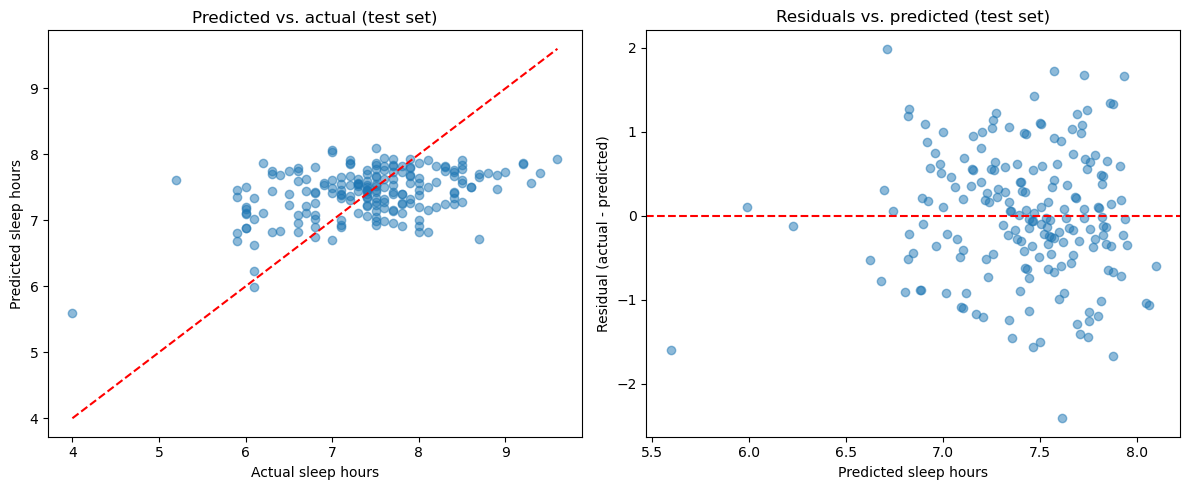

In [33]:
residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Predicted vs actual
axes[0].scatter(y_test, y_test_pred, alpha=0.5)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, color='red', linestyle='--')
axes[0].set_xlabel('Actual sleep hours')
axes[0].set_ylabel('Predicted sleep hours')
axes[0].set_title('Predicted vs. actual (test set)')

# Residuals vs predicted
axes[1].scatter(y_test_pred, residuals, alpha=0.5)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Predicted sleep hours')
axes[1].set_ylabel('Residual (actual - predicted)')
axes[1].set_title('Residuals vs. predicted (test set)')

plt.tight_layout()
plt.show()
